## Practice - Apply the Core Concepts

Use data/web_traffic_daily.csv for all tasks unless stated otherwise.

### Beginner
1. Plot signups over time as a line chart with a title, axis labels, and grid.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("web_traffic_daily.csv",parse_dates=["date"])


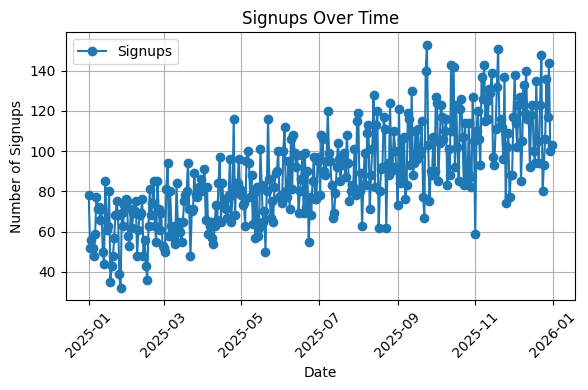

In [3]:
# ===================================
# 1. Signups over time - Line Chart
# ===================================

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    df["date"],
    df["signups"],
    marker="o",
    label="Signups"
)

ax.set_title("Signups Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Signups")

ax.grid(True)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Create a histogram of error_count with 20 bins.

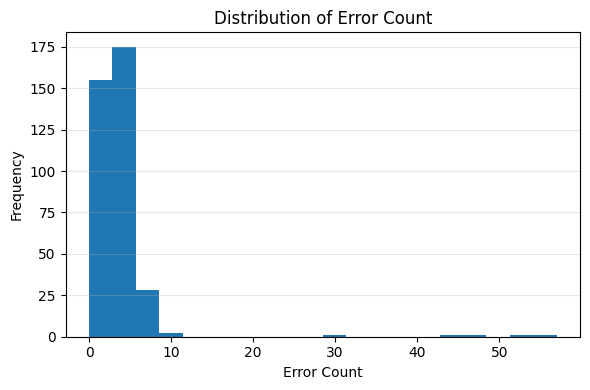

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(
    df["error_count"],
    bins=20
)

ax.set_title("Distribution of Error Count")
ax.set_xlabel("Error Count")
ax.set_ylabel("Frequency")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


3. Create a bar chart comparing total visits for each month.

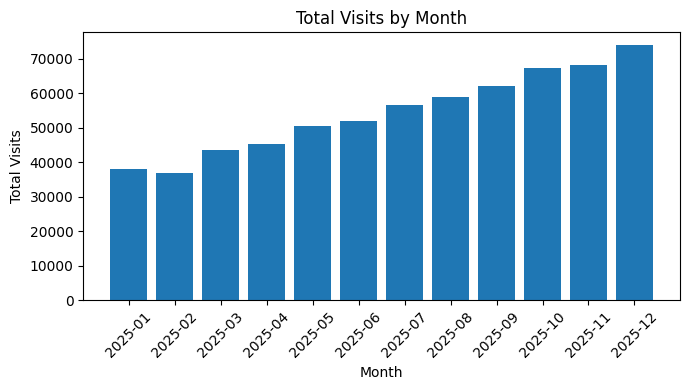

In [7]:
# Create month column
df["month"] = df["date"].dt.to_period("M")
# Calculate total visits per month
monthly_visits = df.groupby("month")["visits"].sum()
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(
    monthly_visits.index.astype(str),
    monthly_visits.values
)
ax.set_title("Total Visits by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Total Visits")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AI/ML & engineering-focused
4. Create a figure with 2 subplots side by side: (a) a scatter of visits vs signups, (b) a box plot of page_load_ms.

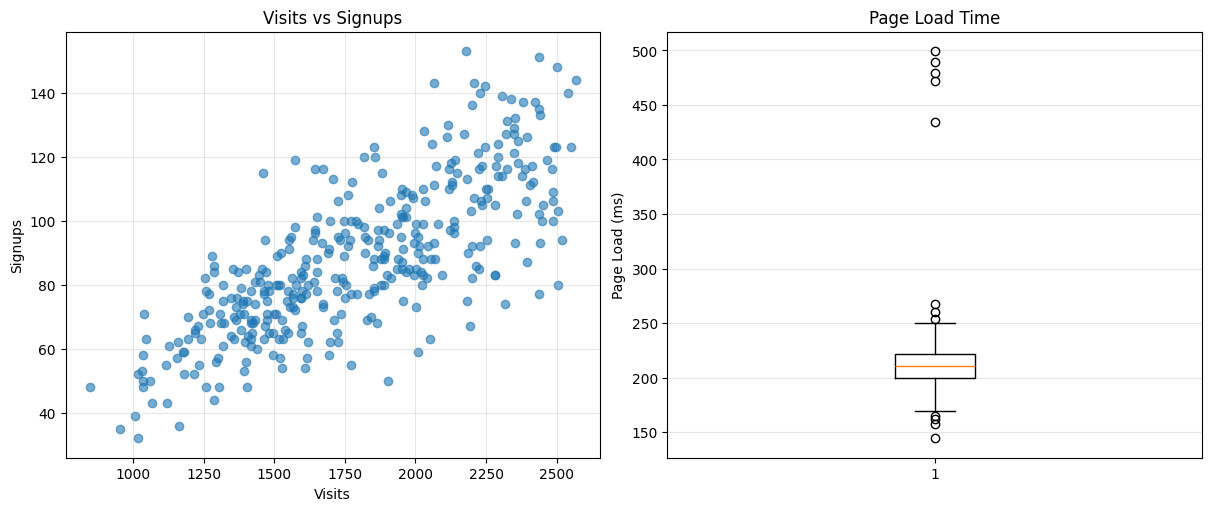

In [13]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)
# ---- (a) Scatter plot ----
axes[0].scatter(
    df["visits"],
    df["signups"],
    alpha=0.6
)
axes[0].set_title("Visits vs Signups")
axes[0].set_xlabel("Visits")
axes[0].set_ylabel("Signups")

axes[0].grid(True, alpha=0.3)

# ---- (b) Box plot ----

axes[1].boxplot(
    df["page_load_ms"]
)
axes[1].set_title("Page Load Time")
axes[1].set_ylabel("Page Load (ms)")

axes[1].grid(axis="y", alpha=0.3)

plt.show()


5. Plot page_load_ms over time, add a 7-day rolling average line, and mark the day with the highest error_count using axvline.

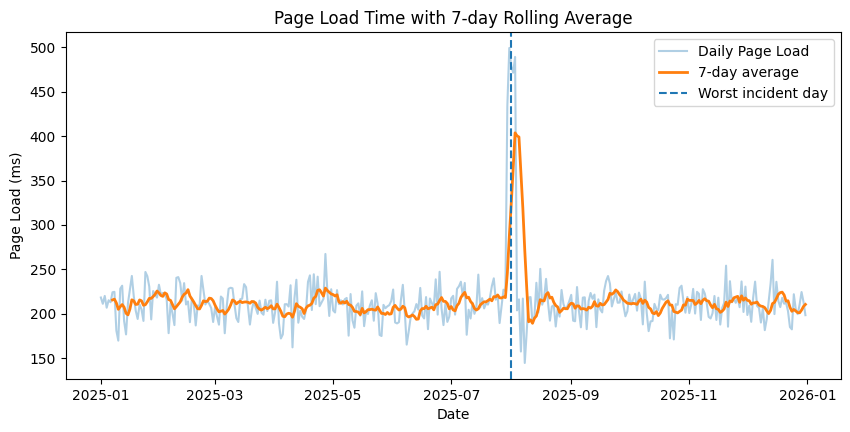

In [15]:
df["page_load_7d_avg"] = df["page_load_ms"].rolling(7).mean()

incident_date = df.loc[df["error_count"].idxmax(), "date"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df["date"],df["page_load_ms"],alpha=0.35,label="Daily Page Load")
ax.plot(df["date"],df["page_load_7d_avg"],linewidth=2,label="7-day average")
ax.axvline(incident_date,linestyle="--",label="Worst incident day")

ax.set_title("Page Load Time with 7-day Rolling Average")
ax.set_xlabel("Date")
ax.set_ylabel("Page Load (ms)")

ax.legend()

plt.show()

6. Recreate the "misleading vs honest" bar chart demonstration using two categories and numbers of your own choice.

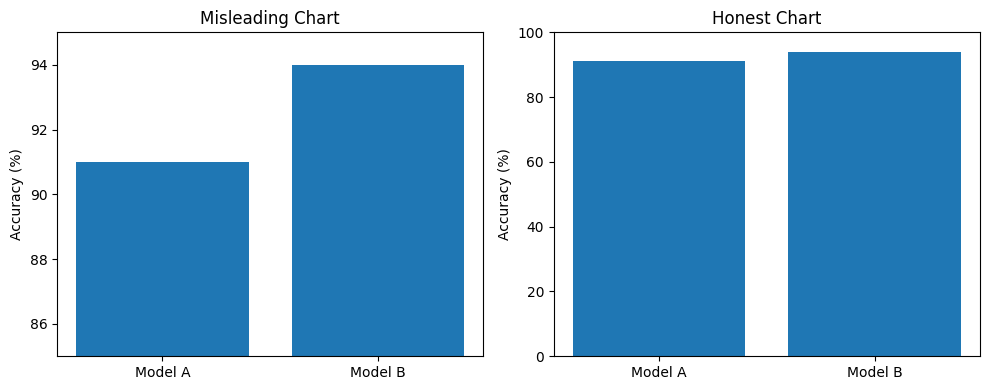

In [16]:
categories = ["Model A", "Model B"]
accuracy = [91, 94]
fig, axes = plt.subplots(1, 2,figsize=(10, 4))
# ---- Misleading chart ----
axes[0].bar(categories,accuracy)
axes[0].set_title("Misleading Chart")
axes[0].set_ylabel("Accuracy (%)")
# Truncated Y-axis
axes[0].set_ylim(85, 95)
# ---- Honest chart ----
axes[1].bar(categories,accuracy)
axes[1].set_title("Honest Chart")
axes[1].set_ylabel("Accuracy (%)")
# Starts from zero
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()


7. Save any one of your figures as a 300-dpi PNG with bbox_inches="tight"

In [17]:
fig.savefig("web_traffic_chart.png",dpi=300,bbox_inches="tight")
print("Figure saved successfully!")

Figure saved successfully!
